In [1]:
import os, re, warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score, roc_curve)

In [3]:
df = pd.read_csv("/content/adult.csv")
print("Original shape:", df.shape)
display(df.head())

Original shape: (48842, 15)


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


In [4]:
df.columns = [c.strip().replace("-", ".") for c in df.columns]

In [5]:
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

In [6]:
df.replace("?", np.nan, inplace=True)
display(df.isnull().sum().sort_values(ascending=False).to_frame("missing"))
before = len(df)
df.dropna(inplace=True)
print(f"Dropped {before-len(df):,} rows; clean shape: {df.shape}")

,missing
occupation,2809
workclass,2799
native.country,857
fnlwgt,0
education,0
educational.num,0
age,0
marital.status,0
relationship,0
gender,0


Dropped 3,620 rows; clean shape: (45222, 15)


In [7]:
df.drop(columns=["fnlwgt", "education"], inplace=True)
print("After dropping fnlwgt and education:", df.shape)

After dropping fnlwgt and education: (45222, 13)


In [8]:
df["income"] = (df["income"] == ">50K").astype("int32")
display(df["income"].value_counts().rename(index={0:"<=50K (0)", 1:">50K (1)"}))
display((df["income"].value_counts(normalize=True)*100).round(2))

,count
income,
<=50K (0),34014
>50K (1),11208


,proportion
income,
0,75.22
1,24.78


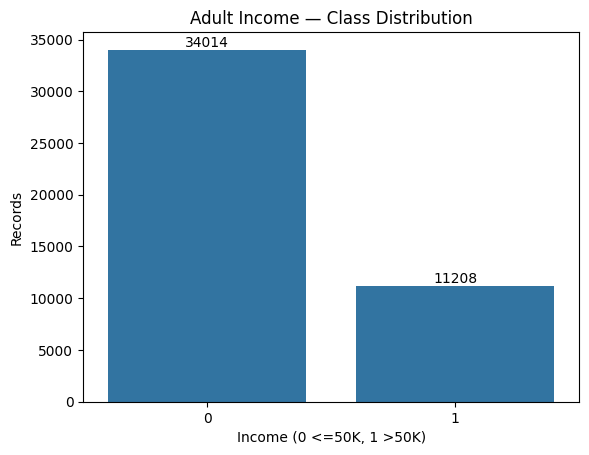

In [9]:
ax = sns.countplot(data=df, x="income")
ax.set(title="Adult Income — Class Distribution", xlabel="Income (0 <=50K, 1 >50K)", ylabel="Records")
for container in ax.containers:
    ax.bar_label(container)
plt.show()

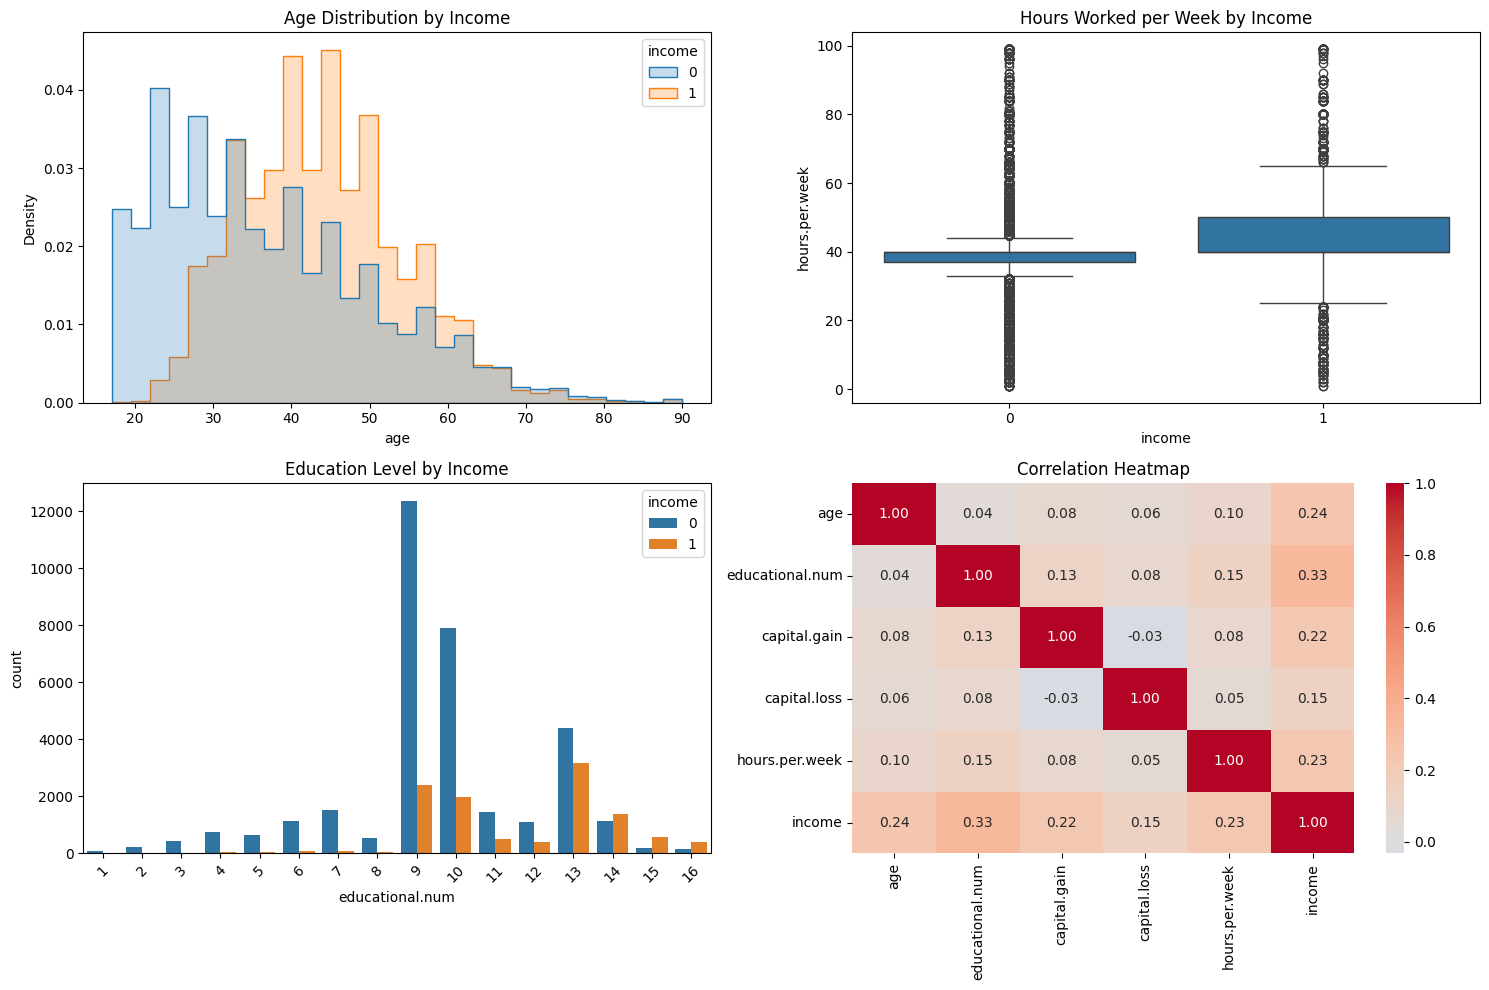

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.histplot(data=df, x="age", hue="income", bins=30, stat="density",
             common_norm=False, element="step", ax=axes[0,0])
axes[0,0].set_title("Age Distribution by Income")
sns.boxplot(data=df, x="income", y="hours.per.week", ax=axes[0,1])
axes[0,1].set_title("Hours Worked per Week by Income")
sns.countplot(data=df, x="educational.num", hue="income", ax=axes[1,0])
axes[1,0].set_title("Education Level by Income")
axes[1,0].tick_params(axis="x", rotation=45)
numeric_for_corr = df.select_dtypes(include=np.number)
sns.heatmap(numeric_for_corr.corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, ax=axes[1,1])
axes[1,1].set_title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [13]:
X_raw = df.drop(columns="income")
y = df["income"].astype("int32")
categorical_cols = X_raw.select_dtypes(include="object").columns.tolist()
numeric_cols = X_raw.select_dtypes(include=np.number).columns.tolist()
X_encoded = pd.get_dummies(X_raw, columns=categorical_cols, drop_first=True, dtype=np.float32)

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train = X_train.copy(); X_test = X_test.copy()
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])
X_train = X_train.astype("float32")
X_test = X_test.astype("float32")
print("Encoded features:", X_train.shape[1])
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train class ratio:\n", y_train.value_counts(normalize=True).sort_index())
print("Test class ratio:\n", y_test.value_counts(normalize=True).sort_index())

Encoded features: 80
Train: (36177, 80) Test: (9045, 80)
Train class ratio:
 income
0    0.752163
1    0.247837
Name: proportion, dtype: float64
Test class ratio:
 income
0    0.752128
1    0.247872
Name: proportion, dtype: float64


In [15]:
def make_optimizer(optimizer):
    if isinstance(optimizer, str):
        key = optimizer.lower()
        if key == "sgd":
            return keras.optimizers.SGD()
        if key == "rmsprop":
            return keras.optimizers.RMSprop()
        if key == "adam":
            return keras.optimizers.Adam()
        raise ValueError(f"Unknown optimizer: {optimizer}")
    return optimizer

def build_ann(input_dim, hidden_units=[128, 64], activation="relu",
              initializer="glorot_uniform", use_batch_norm=False,
              optimizer="adam", loss="binary_crossentropy"):
    layers = [keras.layers.Input(shape=(input_dim,))]
    for units in hidden_units:
        layers.append(keras.layers.Dense(units, kernel_initializer=initializer))
        if use_batch_norm:
            layers.append(keras.layers.BatchNormalization())
        layers.append(keras.layers.Activation(activation))
    layers.append(keras.layers.Dense(1, activation="sigmoid"))
    model = keras.Sequential(layers)
    model.compile(optimizer=make_optimizer(optimizer), loss=loss, metrics=["accuracy"])
    return model

input_dim = X_train.shape[1]
model_base = build_ann(input_dim=input_dim)
model_base.summary()
manual_params = (input_dim*128+128) + (128*64+64) + (64*1+1)
print("Manual Dense parameter count:", manual_params)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,689 (73.00 KB)

 Trainable params: 18,689 (73.00 KB)

 Non-trainable params: 0 (0.00 B)

Manual Dense parameter count: 18689


Epoch 1/20
509/509 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.8350 - loss: 0.3431 - val_accuracy: 0.8460 - val_loss: 0.3285
Epoch 2/20
509/509 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.8538 - loss: 0.3149 - val_accuracy: 0.8502 - val_loss: 0.3227
Epoch 3/20
509/509 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.8556 - loss: 0.3113 - val_accuracy: 0.8521 - val_loss: 0.3210
Epoch 4/20
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8551 - loss: 0.3087 - val_accuracy: 0.8524 - val_loss: 0.3199
Epoch 5/20
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8576 - loss: 0.3058 - val_accuracy: 0.8513 - val_loss: 0.3188
Epoch 6/20
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8593 - loss: 0.3030 - val_accuracy: 0.8546 - val_loss: 0.3189
Epoch 7/20
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8607 - loss: 0.3008 - val_accuracy: 0.8527 - val_loss: 0.3233
Epoch 8/20
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8609 - loss: 0.2982 - val_accuracy: 0

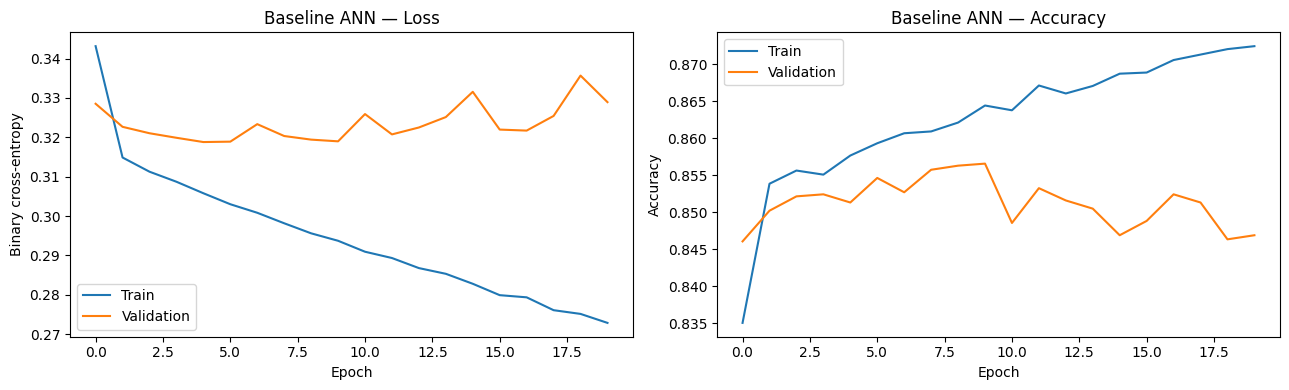

In [17]:
EPOCHS = 20
BATCH_SIZE = 64

history_base = model_base.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
                              validation_split=0.1, verbose=1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(history_base.history["loss"], label="Train")
ax[0].plot(history_base.history["val_loss"], label="Validation")
ax[0].set(title="Baseline ANN — Loss", xlabel="Epoch", ylabel="Binary cross-entropy"); ax[0].legend()
ax[1].plot(history_base.history["accuracy"], label="Train")
ax[1].plot(history_base.history["val_accuracy"], label="Validation")
ax[1].set(title="Baseline ANN — Accuracy", xlabel="Epoch", ylabel="Accuracy"); ax[1].legend()
plt.tight_layout(); plt.show()

              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.90      6803
        >50K       0.74      0.60      0.66      2242

    accuracy                           0.85      9045
   macro avg       0.81      0.76      0.78      9045
weighted avg       0.84      0.85      0.84      9045



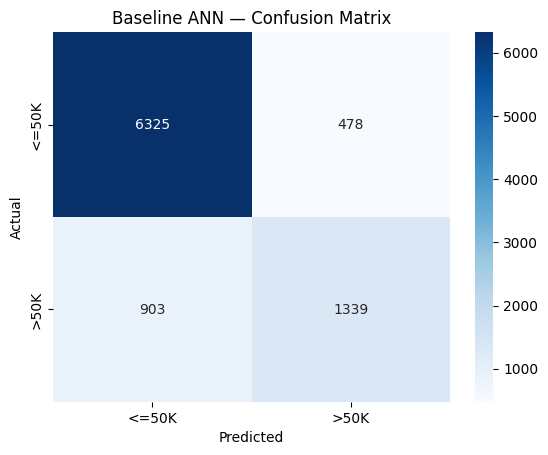

In [18]:
def evaluate_model(model, X=X_test, y=y_test, threshold=0.5, label="Model"):
    prob = model.predict(X, verbose=0).ravel()
    pred = (prob >= threshold).astype(int)
    result = {
        "Model": label,
        "Test Acc": accuracy_score(y, pred),
        "Prec(1)": precision_score(y, pred, zero_division=0),
        "Recall(1)": recall_score(y, pred, zero_division=0),
        "F1(1)": f1_score(y, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y, prob)
    }
    return result, prob, pred

base_result, base_prob, base_pred = evaluate_model(model_base, label="Baseline")
print(classification_report(y_test, base_pred, target_names=["<=50K", ">50K"], zero_division=0))
sns.heatmap(confusion_matrix(y_test, base_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["<=50K", ">50K"], yticklabels=["<=50K", ">50K"])
plt.title("Baseline ANN — Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()
results = [base_result]

In [19]:
activation_models, activation_histories, activation_scores = {}, {}, {}
for act in ["relu", "tanh", "sigmoid", "elu"]:
    print("Training activation:", act)
    m = build_ann(input_dim, activation=act)
    h = m.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
              validation_split=0.1, verbose=0)
    activation_models[act], activation_histories[act] = m, h
    res, _, _ = evaluate_model(m, X_test, y_test, label=f"Activation {act}")
    activation_scores[act] = res

Training activation: relu
Training activation: tanh
Training activation: sigmoid
Training activation: elu


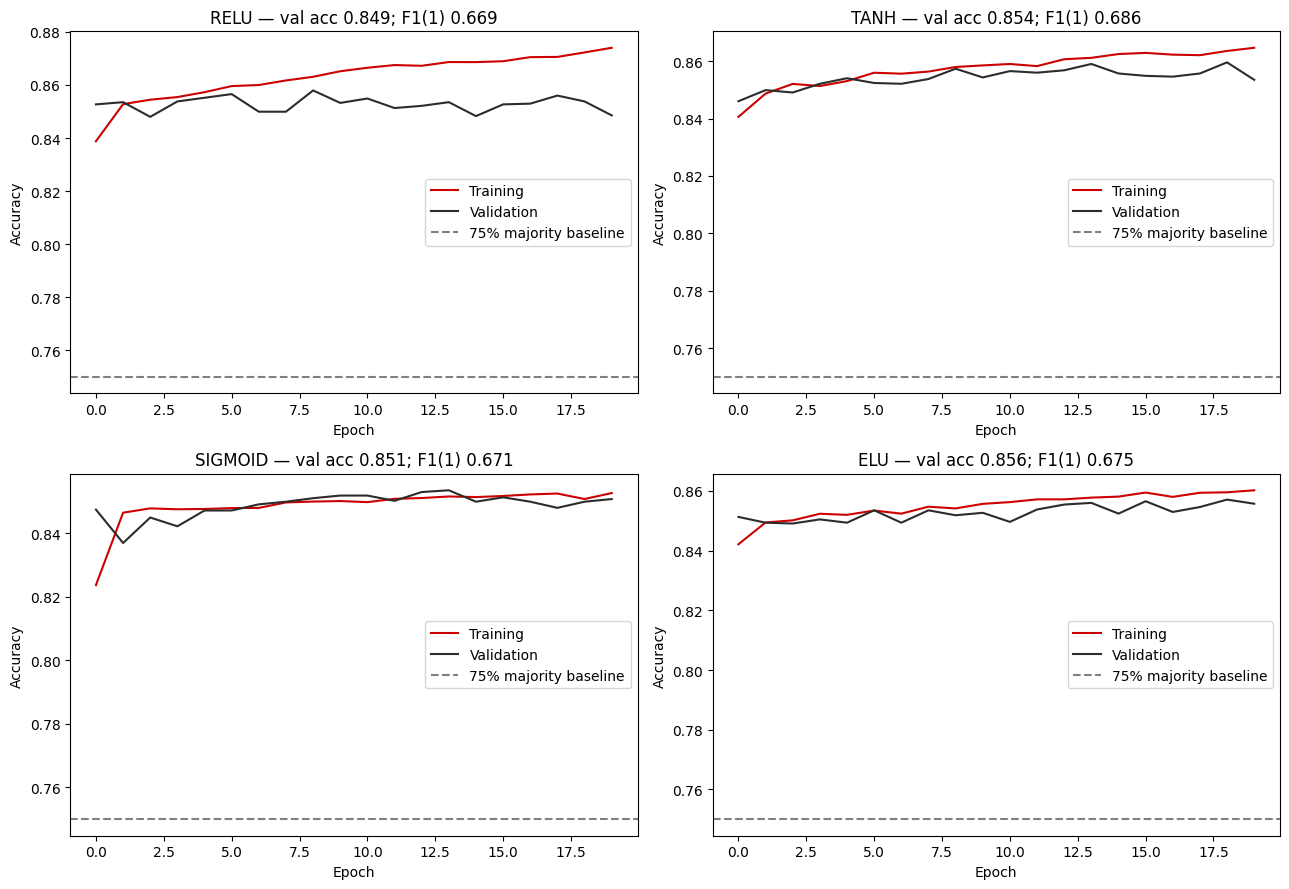

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, act in zip(axes.flat, ["relu", "tanh", "sigmoid", "elu"]):
    h = activation_histories[act]
    ax.plot(h.history["accuracy"], color="#CC0000", label="Training")
    ax.plot(h.history["val_accuracy"], color="#2C2C2C", label="Validation")
    ax.axhline(0.75, linestyle="--", color="gray", label="75% majority baseline")
    ax.set_title(f"{act.upper()} — val acc {h.history['val_accuracy'][-1]:.3f}; F1(1) {activation_scores[act]['F1(1)']:.3f}")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Accuracy"); ax.legend()
plt.tight_layout(); plt.show()

Fraction of zero first-layer outputs: 0.56365625


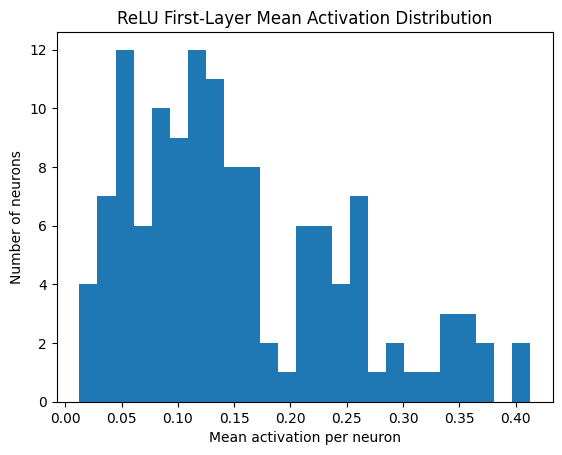

In [21]:
relu_model = activation_models["relu"]
relu_activation = next(layer for layer in relu_model.layers if isinstance(layer, keras.layers.Activation))
relu_intermediate = keras.Model(relu_model.inputs, relu_activation.output)
relu_acts = relu_intermediate.predict(X_test.iloc[:500], verbose=0)
dead_fraction = np.mean(relu_acts == 0)
print("Fraction of zero first-layer outputs:", dead_fraction)
plt.hist(relu_acts.mean(axis=0), bins=25)
plt.title("ReLU First-Layer Mean Activation Distribution")
plt.xlabel("Mean activation per neuron"); plt.ylabel("Number of neurons"); plt.show()

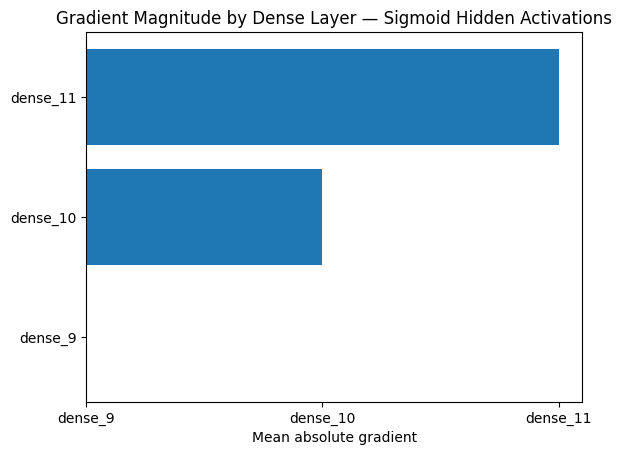

In [22]:
sig_model = activation_models["sigmoid"]
xb = tf.convert_to_tensor(X_train.iloc[:BATCH_SIZE].to_numpy(), dtype=tf.float32)
yb = tf.convert_to_tensor(y_train.iloc[:BATCH_SIZE].to_numpy().reshape(-1,1), dtype=tf.float32)
with tf.GradientTape() as tape:
    yp = sig_model(xb, training=True)
    loss_value = tf.reduce_mean(keras.losses.binary_crossentropy(yb, yp))
grads = tape.gradient(loss_value, sig_model.trainable_variables)
layer_gradients = {}
for layer in sig_model.layers:
    if isinstance(layer, keras.layers.Dense):
        indices = [i for i,v in enumerate(sig_model.trainable_variables)
                   if v is layer.kernel or v is layer.bias]
        vals = [tf.reduce_mean(tf.abs(grads[i])).numpy() for i in indices if grads[i] is not None]
        layer_gradients[layer.name] = float(np.mean(vals)) if vals else 0.0
plt.barh(list(layer_gradients), list(layer_gradients))
plt.title("Gradient Magnitude by Dense Layer — Sigmoid Hidden Activations")
plt.xlabel("Mean absolute gradient"); plt.show()

In [23]:
activation_summary = pd.DataFrame([
    ["ReLU", "max(0,x)", "[0,∞)", "No", "Low–moderate", "Possible", activation_scores["relu"]["F1(1)"]],
    ["Tanh", "tanh(x)", "[-1,1]", "Yes", "Moderate when saturated", "No", activation_scores["tanh"]["F1(1)"]],
    ["Sigmoid hidden", "1/(1+e^-x)", "(0,1)", "No", "High", "No", activation_scores["sigmoid"]["F1(1)"]],
    ["ELU", "x if x>0 else α(e^x−1)", "(-α,∞)", "Approximately", "Lower than sigmoid", "Less likely", activation_scores["elu"]["F1(1)"]],
], columns=["Activation","Formula","Output Range","Zero-Centred","Vanishing Gradient Risk","Dead Neuron Risk","Test F1(1)"])
display(activation_summary)

,Activation,Formula,Output Range,Zero-Centred,Vanishing Gradient Risk,Dead Neuron Risk,Test F1(1)
0,ReLU,"max(0,x)","[0,∞)",No,Low–moderate,Possible,0.668929
1,Tanh,tanh(x),"[-1,1]",Yes,Moderate when saturated,No,0.685819
2,Sigmoid hidden,1/(1+e^-x),"(0,1)",No,High,No,0.671180
3,ELU,x if x>0 else α(e^x−1),"(-α,∞)",Approximately,Lower than sigmoid,Less likely,0.674722


In [24]:
initializers = ["glorot_uniform", "glorot_normal", "he_uniform", "he_normal", "zeros"]
init_models, init_histories, init_scores, initial_weights = {}, {}, {}, {}
for init in initializers:
    print("Training initializer:", init)
    m = build_ann(input_dim, activation="relu", initializer=init)
    first_dense = next(layer for layer in m.layers if isinstance(layer, keras.layers.Dense))
    initial_weights[init] = first_dense.get_weights()[0].copy()
    h = m.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
              validation_split=0.1, verbose=0)
    init_models[init], init_histories[init] = m, h
    res, _, _ = evaluate_model(m, X_test, y_test, label=f"Init {init}")
    init_scores[init] = res

Training initializer: glorot_uniform
Training initializer: glorot_normal
Training initializer: he_uniform
Training initializer: he_normal
Training initializer: zeros


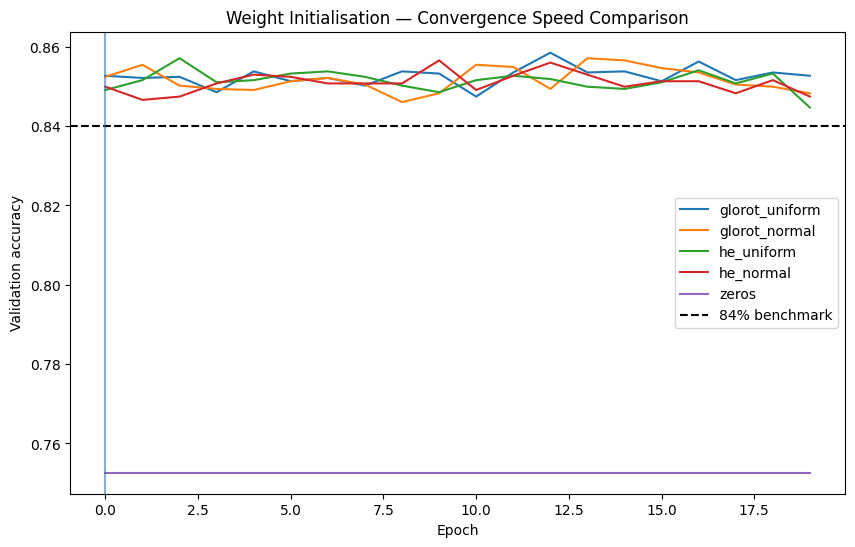

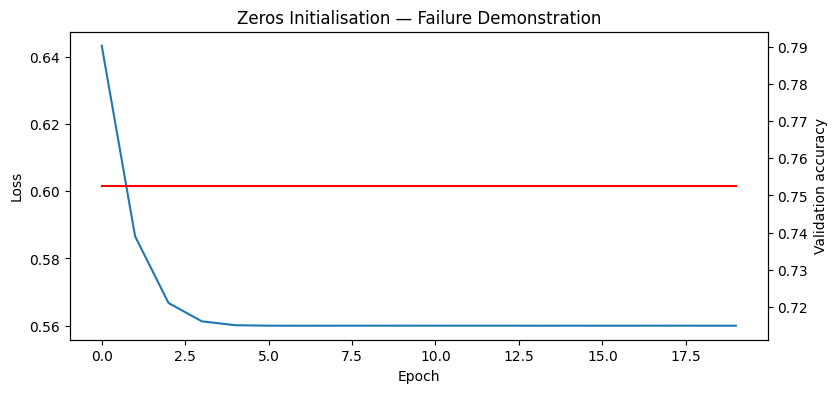

In [25]:
plt.figure(figsize=(10,6))
for init, h in init_histories.items():
    plt.plot(h.history["val_accuracy"], label=init)
plt.axhline(.84, color="black", linestyle="--", label="84% benchmark")
for init, h in init_histories.items():
    if init != "zeros":
        crossed = np.where(np.array(h.history["val_accuracy"]) >= .82)[0]
        if len(crossed): plt.axvline(crossed[0], alpha=.18)
plt.title("Weight Initialisation — Convergence Speed Comparison")
plt.xlabel("Epoch"); plt.ylabel("Validation accuracy"); plt.legend(); plt.show()

zero_h = init_histories["zeros"]
fig, ax1 = plt.subplots(figsize=(9,4))
ax1.plot(zero_h.history["loss"], label="Training loss")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss")
ax2 = ax1.twinx()
ax2.plot(zero_h.history["val_accuracy"], color="red", label="Validation accuracy")
ax2.set_ylabel("Validation accuracy")
plt.title("Zeros Initialisation — Failure Demonstration")
plt.show()

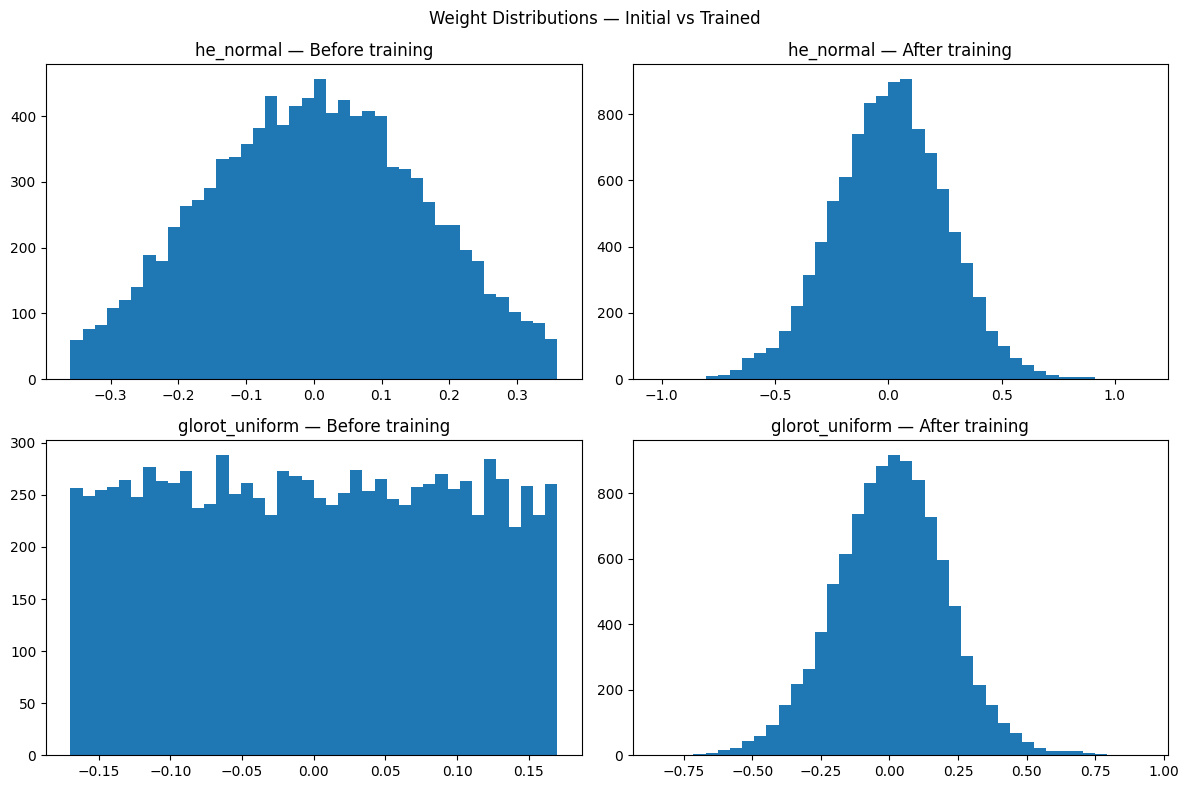

In [26]:
fig, axes = plt.subplots(2,2,figsize=(12,8))
for ax, init, when in [(axes[0,0],"he_normal","Before"), (axes[0,1],"he_normal","After"),
                       (axes[1,0],"glorot_uniform","Before"), (axes[1,1],"glorot_uniform","After")]:
    vals = initial_weights[init] if when=="Before" else next(
        l for l in init_models[init].layers if isinstance(l, keras.layers.Dense)).get_weights()[0]
    ax.hist(vals.ravel(), bins=40)
    ax.set_title(f"{init} — {when} training")
plt.suptitle("Weight Distributions — Initial vs Trained")
plt.tight_layout(); plt.show()

In [27]:
model_mse = build_ann(input_dim, activation="relu", initializer="he_normal", loss="mean_squared_error")
history_mse = model_mse.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
                            validation_split=0.1, verbose=0)
mse_result, mse_prob, mse_pred = evaluate_model(model_mse, label="MSE")

In [28]:
class_values = np.array([0,1])
cw = compute_class_weight(class_weight="balanced", classes=class_values, y=y_train)
class_weight_dict = {0: float(cw[0]), 1: float(cw[1])}
print("Class weights:", class_weight_dict)
model_wbce = build_ann(input_dim, activation="relu", initializer="he_normal")
history_wbce = model_wbce.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
                              validation_split=0.1, class_weight=class_weight_dict, verbose=0)
wbce_result, wbce_prob, wbce_pred = evaluate_model(model_wbce, label="Weighted BCE")

Class weights: {0: 0.6647495498144133, 1: 2.0174548293553425}


In [29]:
def focal_loss(gamma=2.0, alpha=0.25):
    def loss(y_true, y_pred):
        y_true = tf.reshape(tf.cast(y_true, tf.float32), (-1, 1))
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1-1e-7)
        bce = -y_true*tf.math.log(y_pred) - (1-y_true)*tf.math.log(1-y_pred)
        weight = alpha*y_true*(1-y_pred)**gamma + (1-alpha)*(1-y_true)*y_pred**gamma
        return tf.reduce_mean(weight*bce)
    return loss

model_focal = build_ann(input_dim, activation="relu", initializer="he_normal", loss=focal_loss())
history_focal = model_focal.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
                                validation_split=0.1, verbose=0)
focal_result, focal_prob, focal_pred = evaluate_model(model_focal, label="Focal Loss")

,Model,Test Acc,Prec(1),Recall(1),F1(1),ROC-AUC
0,Baseline,0.847319,0.736929,0.597235,0.659768,0.904367
1,MSE,0.849530,0.734683,0.615076,0.669580,0.905893
2,Weighted BCE,0.801879,0.567406,0.844781,0.678853,0.899682
3,Focal Loss,0.826202,0.859442,0.357270,0.504726,0.896629


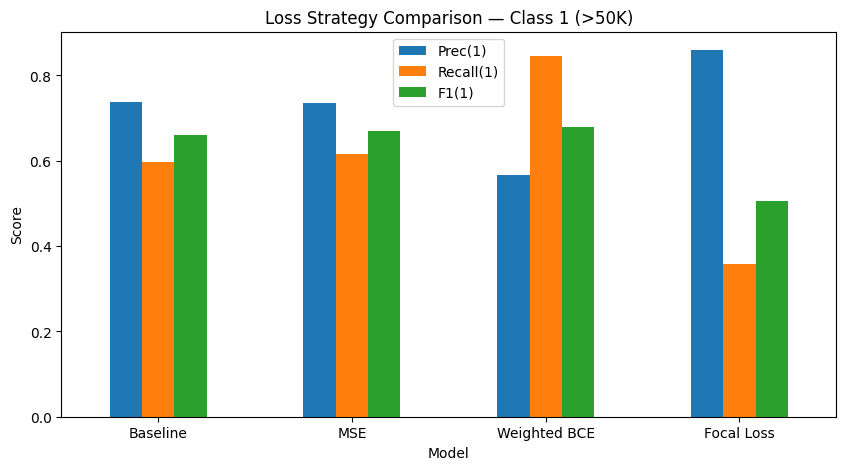

In [30]:
loss_results = [base_result, mse_result, wbce_result, focal_result]
display(pd.DataFrame(loss_results))
metrics = ["Prec(1)", "Recall(1)", "F1(1)"]
loss_metric_df = pd.DataFrame(loss_results).set_index("Model")[metrics]
loss_metric_df.plot(kind="bar", figsize=(10,5))
plt.title("Loss Strategy Comparison — Class 1 (>50K)")
plt.ylabel("Score"); plt.xticks(rotation=0); plt.show()

In [31]:
def build_bn_model(order="before"):
    layers = [keras.layers.Input(shape=(input_dim,))]
    for units in [128,64]:
        layers.append(keras.layers.Dense(units, kernel_initializer="he_normal"))
        if order == "before":
            layers.extend([keras.layers.BatchNormalization(), keras.layers.Activation("relu")])
        else:
            layers.extend([keras.layers.Activation("relu"), keras.layers.BatchNormalization()])
    layers.append(keras.layers.Dense(1, activation="sigmoid"))
    m = keras.Sequential(layers)
    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return m

model_bn = build_bn_model("before")
model_bn.summary()
history_bn = model_bn.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
                          validation_split=0.1, verbose=0)
bn_result, bn_prob, bn_pred = evaluate_model(model_bn, label="BatchNorm")

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_39 (Dense)                │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_26 (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_27 (Activation)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,457 (76.00 KB)

 Trainable params: 19,073 (74.50 KB)

 Non-trainable params: 384 (1.50 KB)

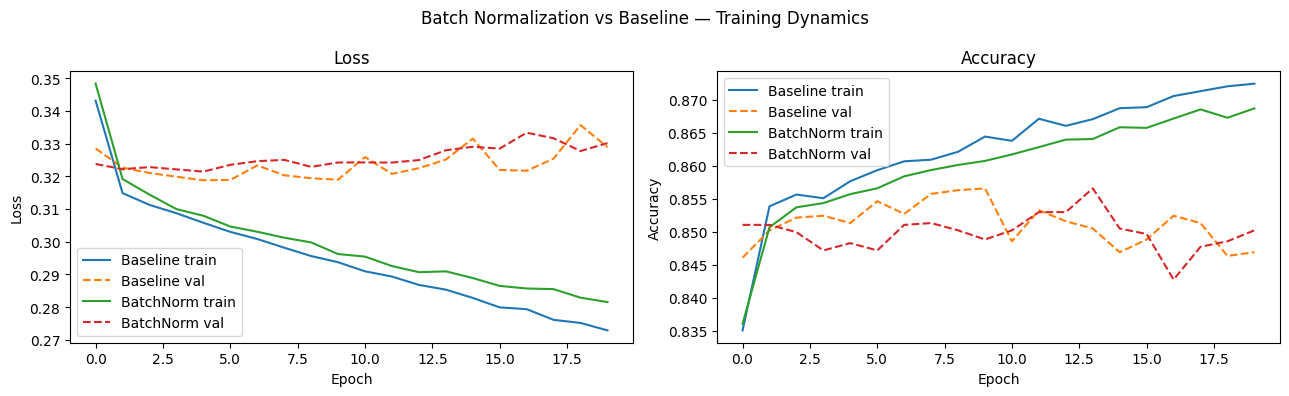

In [32]:
fig, ax = plt.subplots(1,2,figsize=(13,4))
for h, name in [(history_base,"Baseline"),(history_bn,"BatchNorm")]:
    ax[0].plot(h.history["loss"], label=f"{name} train")
    ax[0].plot(h.history["val_loss"], linestyle="--", label=f"{name} val")
    ax[1].plot(h.history["accuracy"], label=f"{name} train")
    ax[1].plot(h.history["val_accuracy"], linestyle="--", label=f"{name} val")
ax[0].set(title="Loss", xlabel="Epoch", ylabel="Loss"); ax[0].legend()
ax[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy"); ax[1].legend()
plt.suptitle("Batch Normalization vs Baseline — Training Dynamics")
plt.tight_layout(); plt.show()

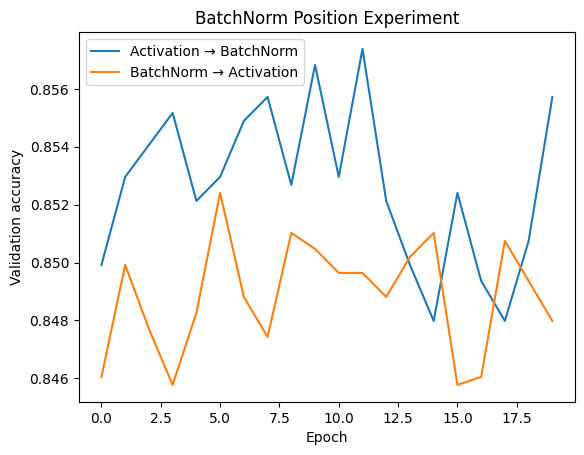

In [33]:
model_bn_after = build_bn_model("after")
hist_bn_after = model_bn_after.fit(X_train, y_train, epochs=min(30,EPOCHS), batch_size=BATCH_SIZE,
                                  validation_split=0.1, verbose=0)
model_bn_before = build_bn_model("before")
hist_bn_before = model_bn_before.fit(X_train, y_train, epochs=min(30,EPOCHS), batch_size=BATCH_SIZE,
                                    validation_split=0.1, verbose=0)
plt.plot(hist_bn_after.history["val_accuracy"], label="Activation → BatchNorm")
plt.plot(hist_bn_before.history["val_accuracy"], label="BatchNorm → Activation")
plt.title("BatchNorm Position Experiment"); plt.xlabel("Epoch"); plt.ylabel("Validation accuracy")
plt.legend(); plt.show()

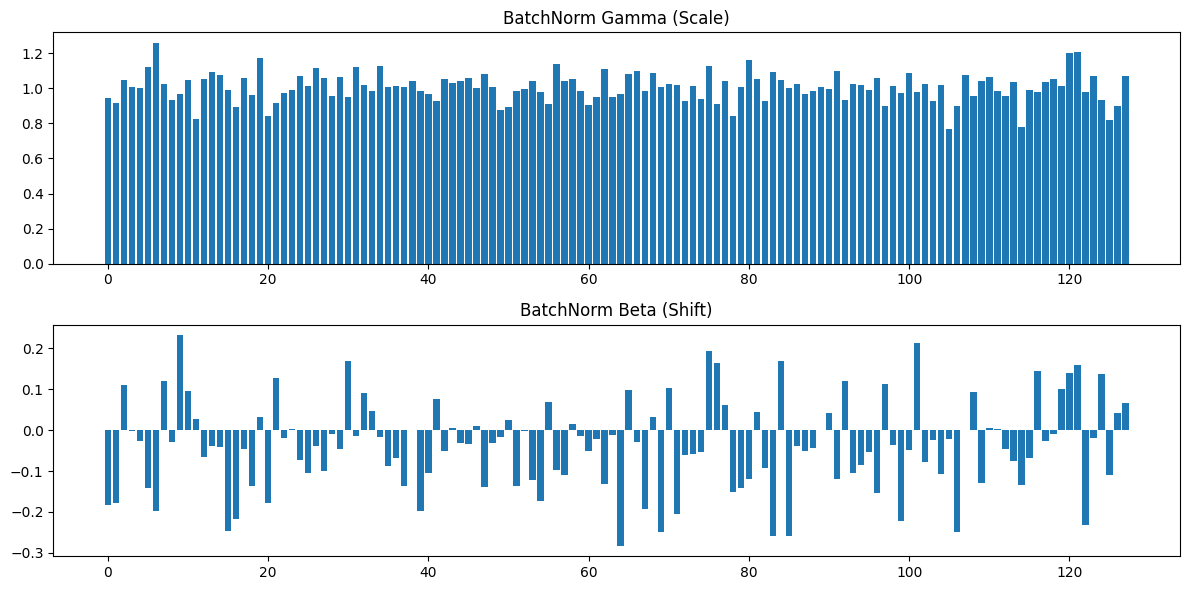

Near-zero |gamma| units: 0


In [34]:
bn_layer = next(layer for layer in model_bn.layers if isinstance(layer, keras.layers.BatchNormalization))
gamma, beta, running_mean, running_var = bn_layer.get_weights()
fig, axes = plt.subplots(2,1,figsize=(12,6))
axes[0].bar(np.arange(len(gamma)), gamma); axes[0].set_title("BatchNorm Gamma (Scale)")
axes[1].bar(np.arange(len(beta)), beta); axes[1].set_title("BatchNorm Beta (Shift)")
plt.tight_layout(); plt.show()
print("Near-zero |gamma| units:", int(np.sum(np.abs(gamma)<0.1)))

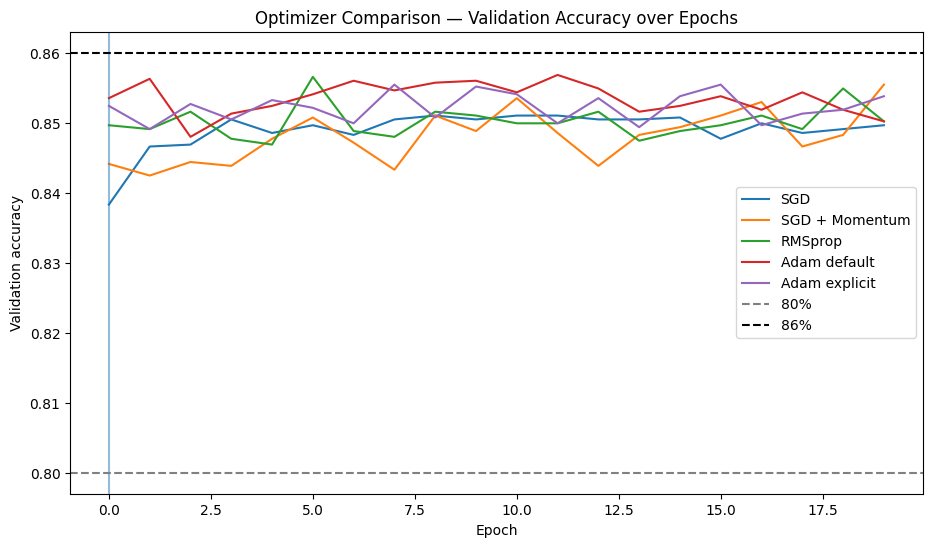

In [35]:
optimizer_specs = {
    "SGD": "sgd",
    "SGD + Momentum": keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    "RMSprop": "rmsprop",
    "Adam default": "adam",
    "Adam explicit": keras.optimizers.Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.999)
}
optimizer_models, optimizer_histories, optimizer_scores = {}, {}, {}
for name, opt in optimizer_specs.items():
    m = build_ann(input_dim, activation="relu", initializer="he_normal",
                  use_batch_norm=True, optimizer=opt)
    h = m.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
              validation_split=0.1, verbose=0)
    optimizer_models[name], optimizer_histories[name] = m, h
    optimizer_scores[name] = evaluate_model(m, label=name)[0]

plt.figure(figsize=(11,6))
for name,h in optimizer_histories.items():
    vals=np.array(h.history["val_accuracy"])
    plt.plot(vals,label=name)
    crossed=np.where(vals>=.83)[0]
    if len(crossed): plt.axvline(crossed[0], alpha=.12)
plt.axhline(.80,linestyle="--",color="gray",label="80%")
plt.axhline(.86,linestyle="--",color="black",label="86%")
plt.title("Optimizer Comparison — Validation Accuracy over Epochs")
plt.xlabel("Epoch"); plt.ylabel("Validation accuracy"); plt.legend(); plt.show()

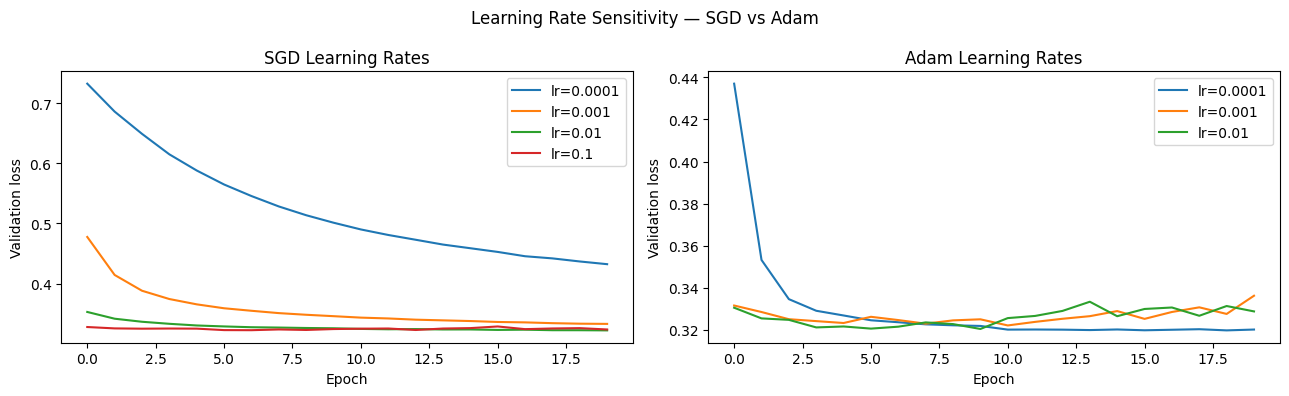

In [36]:
lr_histories = {"SGD": {}, "Adam": {}}
for lr in [0.0001, 0.001, 0.01, 0.1]:
    m = build_ann(input_dim, activation="relu", initializer="he_normal",
                  use_batch_norm=True, optimizer=keras.optimizers.SGD(learning_rate=lr))
    lr_histories["SGD"][lr] = m.fit(X_train,y_train,epochs=min(30,EPOCHS),batch_size=BATCH_SIZE,
                                   validation_split=0.1,verbose=0).history
for lr in [0.0001, 0.001, 0.01]:
    m = build_ann(input_dim, activation="relu", initializer="he_normal",
                  use_batch_norm=True, optimizer=keras.optimizers.Adam(learning_rate=lr))
    lr_histories["Adam"][lr] = m.fit(X_train,y_train,epochs=min(30,EPOCHS),batch_size=BATCH_SIZE,
                                    validation_split=0.1,verbose=0).history
fig,axes=plt.subplots(1,2,figsize=(13,4))
for lr,h in lr_histories["SGD"].items(): axes[0].plot(h["val_loss"],label=f"lr={lr}")
for lr,h in lr_histories["Adam"].items(): axes[1].plot(h["val_loss"],label=f"lr={lr}")
axes[0].set_title("SGD Learning Rates"); axes[1].set_title("Adam Learning Rates")
for ax in axes: ax.set_xlabel("Epoch"); ax.set_ylabel("Validation loss"); ax.legend()
plt.suptitle("Learning Rate Sensitivity — SGD vs Adam"); plt.tight_layout(); plt.show()

In [38]:
use_weighted = wbce_result["F1(1)"] > base_result["F1(1)"]
final_loss = "binary_crossentropy"
final_model = build_bn_model("before")
if use_weighted:
    final_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
final_history = final_model.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
                                validation_split=0.1,
                                class_weight=class_weight_dict if use_weighted else None,
                                verbose=1)
final_result, final_prob, final_pred = evaluate_model(final_model, label="Final Combined")
print("Weighted BCE selected:", use_weighted)
print(classification_report(y_test, final_pred, target_names=["<=50K",">50K"], zero_division=0))

Epoch 1/20
509/509 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.7866 - loss: 0.4082 - val_accuracy: 0.8112 - val_loss: 0.3759
Epoch 2/20
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8079 - loss: 0.3771 - val_accuracy: 0.8118 - val_loss: 0.3759
Epoch 3/20
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8112 - loss: 0.3705 - val_accuracy: 0.8104 - val_loss: 0.3752
Epoch 4/20
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8150 - loss: 0.3662 - val_accuracy: 0.8098 - val_loss: 0.3778
Epoch 5/20
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8144 - loss: 0.3631 - val_accuracy: 0.8090 - val_loss: 0.3739
Epoch 6/20
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8165 - loss: 0.3602 - val_accuracy: 0.8021 - val_loss: 0.3882
Epoch 7/20
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8162 - loss: 0.3583 - val_accuracy: 0.8101 - val_loss: 0.3759
Epoch 8/20
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8174 - loss: 0.3556 - val_accuracy: 0.

In [39]:
comparison_rows = [
    base_result,
    activation_scores[max(activation_scores, key=lambda k: activation_scores[k]["F1(1)"])],
    init_scores[max(init_scores, key=lambda k: init_scores[k]["F1(1)"])],
    wbce_result, focal_result, bn_result, final_result
]
comparison = pd.DataFrame(comparison_rows)
comparison.insert(1, "Activation/Config", ["ReLU baseline",
    "Best activation", "Best initializer", "ReLU + He", "ReLU + He", "ReLU + He + BN", "Combined"])
comparison["BatchNorm"] = ["No","No","No","No","No","Yes","Yes"]
comparison["Optimizer"] = ["Adam","Adam","Adam","Adam","Adam","Adam","Adam"]
display(comparison.style.highlight_max(subset=["F1(1)","ROC-AUC"], color="#ffcccc"))

,Model,Activation/Config,Test Acc,Prec(1),Recall(1),F1(1),ROC-AUC,BatchNorm,Optimizer
0,Baseline,ReLU baseline,0.847319,0.736929,0.597235,0.659768,0.904367,No,Adam
1,Activation tanh,Best activation,0.848867,0.707444,0.665477,0.685819,0.910299,No,Adam
2,Init glorot_normal,Best initializer,0.843892,0.682498,0.692239,0.687334,0.903812,No,Adam
3,Weighted BCE,ReLU + He,0.801879,0.567406,0.844781,0.678853,0.899682,No,Adam
4,Focal Loss,ReLU + He,0.826202,0.859442,0.357270,0.504726,0.896629,No,Adam
5,BatchNorm,ReLU + He + BN,0.847430,0.719898,0.629349,0.671585,0.903799,Yes,Adam
6,Final Combined,Combined,0.799226,0.562172,0.859054,0.679605,0.902044,Yes,Adam


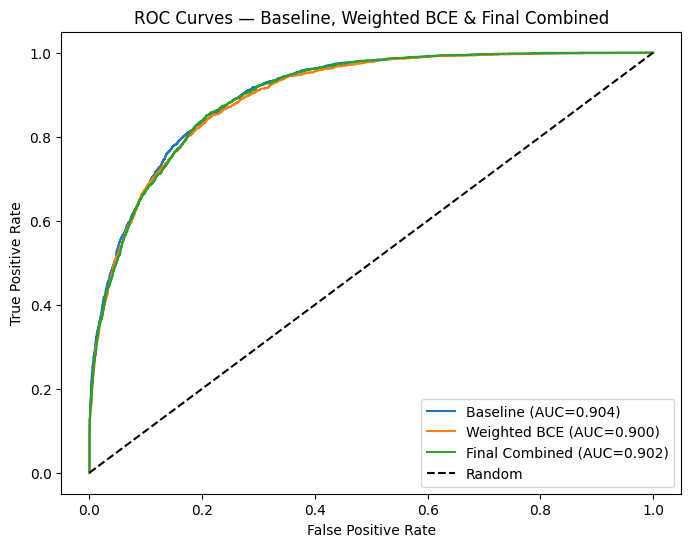

In [40]:
plt.figure(figsize=(8,6))
for name, probs in [("Baseline",base_prob),("Weighted BCE",wbce_prob),("Final Combined",final_prob)]:
    fpr,tpr,_ = roc_curve(y_test,probs)
    auc = roc_auc_score(y_test,probs)
    plt.plot(fpr,tpr,label=f"{name} (AUC={auc:.3f})")
plt.plot([0,1],[0,1],"k--",label="Random")
plt.title("ROC Curves — Baseline, Weighted BCE & Final Combined")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.legend(); plt.show()

Final interpretation: Use the results table to identify the strongest class-1 F1 and ROC-AUC. State which single change (activation, initializer, loss, BatchNorm or optimizer) produced the largest measured improvement over the baseline. Explain the mechanism and mention any precision/recall trade-off. Do not claim an experiment won unless the recorded metrics support it.